## A search

`probatum.search` runs a policy over a space of its parameters on the bars before a
holdout, and keeps every trial. Here a crossing of two exponential averages on hourly
Bitcoin bars of 2024 and 2025, the last 30% held out: every point of a grid of the two
lengths, then Optuna's TPE on the same space, then the winner's one look at the bars no
trial saw.

In [1]:
import pathlib

import exchange_router
import matplotlib.colors
import matplotlib.pyplot
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 2.0.0, exchange-router 3.0.1


### The bars

Binance's hourly BTCUSDT, fetched once into `bars/`.

In [2]:
PATH = pathlib.Path("../bars/binance-spot-btcusdt-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    data.save(path=PATH)

data

Data(BTCUSDT, 1h, 17544 bars from 2024-01-01 00:00 to 2025-12-31 23:00)

### The policy and its space

A function of the bars a trial runs on and of its parameters, returning weights: the whole
account while the fast average is above the slow one. Its weights run whole in Rust, so a
grid or random search runs its trials many to a call.

In [3]:
def crossing(data, fast, slow):
    up   = probatum.ta.ema(data.close, length=fast)
    down = probatum.ta.ema(data.close, length=slow)
    return numpy.where(up > down, 1.0, 0.0)


space = {"fast": probatum.Int(low=6, high=72, step=6),
         "slow": probatum.Int(low=96, high=528, step=24)}

space

{'fast': Int(6, 72, step=6), 'slow': Int(96, 528, step=24)}

### Every point of a grid

Twelve fast lengths by nineteen slow ones, each a trial scored on its Sharpe over the bars
before the holdout. Before it trusts any trial, the search runs the first one again on the
bars cut short where its decisions change, and refuses a policy whose decisions there move.

In [4]:
grid = probatum.search(crossing, space=space, data=data, venue="binance_spot",
                       sampler="grid", trials=228, holdout=0.3, seed=7)

grid

Study(228 trials of crossing by grid, best sharpe 2.12 over 12,281 bars; 5,263 held out, not yet read)

### The trials

Each trial's parameters, its state and score, and the statistics its run recorded.

In [5]:
trials = grid.trials.to_pandas()

trials.sort_values(by="score", ascending=False)[
    ["number", "fast", "slow", "score", "total_return_pct", "max_drawdown_pct",
     "num_trades"]].head(n=8).round(decimals=2)

,number,fast,slow,score,total_return_pct,max_drawdown_pct,num_trades
146,146,48,408,2.12,163.31,24.75,16
145,145,48,384,2.11,161.49,23.93,17
127,127,42,408,2.10,160.31,23.12,17
147,147,48,432,2.08,158.29,22.96,15
163,163,54,360,2.06,154.78,27.24,16
164,164,54,384,2.03,151.33,25.14,16
142,142,48,312,2.01,148.14,24.00,22
128,128,42,432,2.01,149.06,26.20,17


### The landscape

Every trial's Sharpe on the grid of its two lengths, the winner ringed.

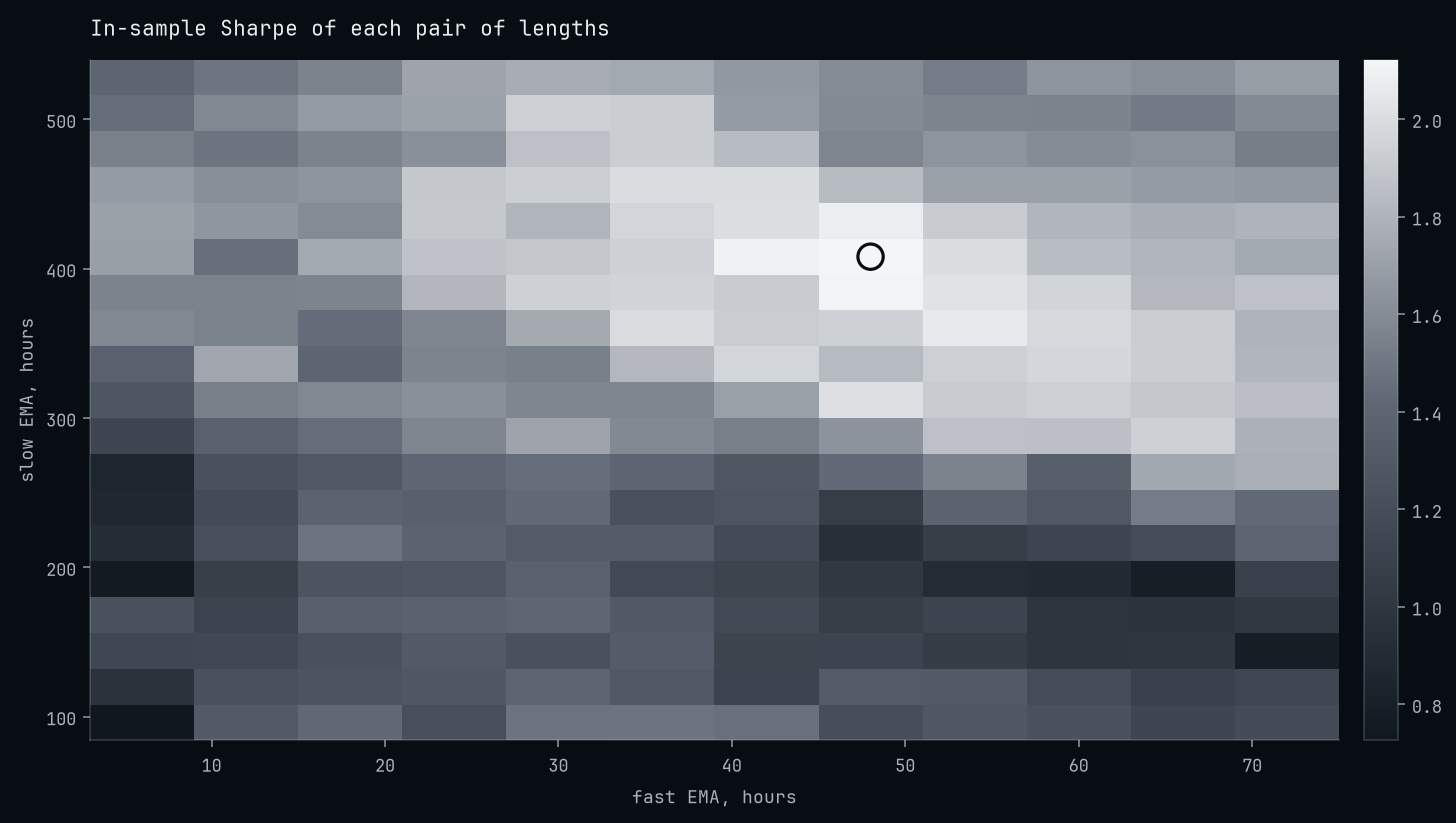

In [6]:
landscape = trials.pivot(index="slow", columns="fast", values="score")

figure, axes = matplotlib.pyplot.subplots(figsize=(10.0, 5.6))
ink = matplotlib.colors.LinearSegmentedColormap.from_list(
    name="ink", colors=["#0f171f", "#5f6874", "#f4f5f7"])
shown = axes.pcolormesh(landscape.columns, landscape.index, landscape.values, cmap=ink,
                        shading="nearest")
axes.scatter([grid.best_params["fast"]], [grid.best_params["slow"]], s=160.0,
             facecolors="none", edgecolors="#070d13", linewidths=1.6)
axes.set_xlabel(xlabel="fast EMA, hours")
axes.set_ylabel(ylabel="slow EMA, hours")
axes.grid(visible=False)
axes.set_title(label="In-sample Sharpe of each pair of lengths")
figure.colorbar(mappable=shown, ax=axes, fraction=0.03, pad=0.02)
matplotlib.pyplot.show()

### The winner's neighbours, and each parameter's share

`plateau` counts, at each distance from the winner in the space's own scale, the share of
the trials there that scored past a level, here half the winner's score. `importance` is
the share of the scores' variation each parameter explains on its own, beside what chance
gives.

In [7]:
print(grid.plateau(level=grid.best_score / 2.0))

grid.importance()

        trials  passed     share
radius                          
0.05         0       0       NaN
0.10         4       4  1.000000
0.15        14      14  1.000000
0.20        26      26  1.000000
0.25        40      40  1.000000
0.30        60      60  1.000000
0.35        71      71  1.000000
0.40        94      93  0.989362
0.45       107     105  0.981308
0.50       127     124  0.976378

              value
level      1.061091
objective    sharpe
direction  maximize


importance    chance  groups
parameter                              
fast         0.086272  0.039648      10
slow         0.697234  0.039648      10

       value
trials   228

### TPE on the same space

Optuna's TPE chooses each trial from the ones before it, so it runs them one at a time. Its
best score so far at each trial, against the best of the whole grid.

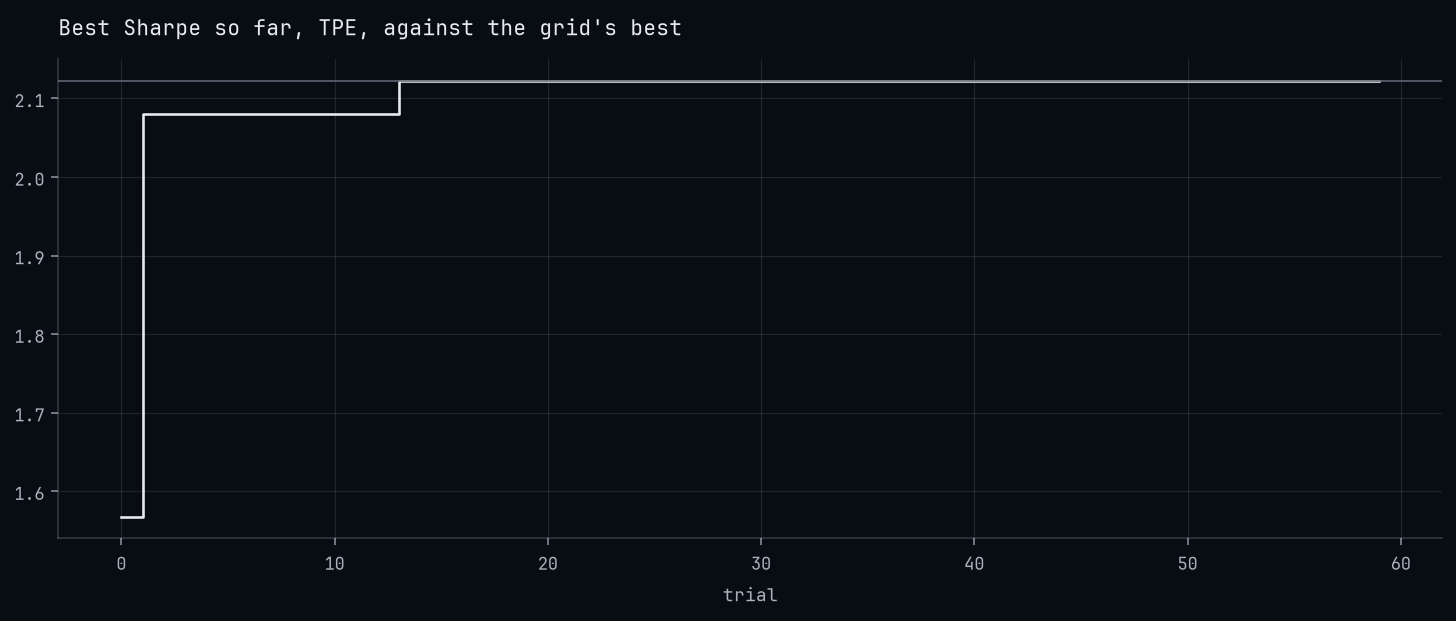

TPE {'fast': 48, 'slow': 408} 2.122, grid {'fast': 48, 'slow': 408} 2.122


In [8]:
tpe = probatum.search(crossing, space=space, data=data, venue="binance_spot",
                      sampler="tpe", trials=60, holdout=0.3, seed=7)

scores = tpe.trials.to_pandas()["score"]

axes = scores.cummax().plot(title="Best Sharpe so far, TPE, against the grid's best",
                            xlabel="trial", drawstyle="steps-post")
axes.axhline(y=grid.best_score, color="C3", linewidth=0.8)
matplotlib.pyplot.show()

print(f"TPE {tpe.best_params} {tpe.best_score:.3f}, grid {grid.best_params} "
      f"{grid.best_score:.3f}")

### The one look at the holdout

`evaluate_holdout` runs the grid's winner once on the bars no trial saw, its warm-up inside
them, and counts the look. The Study's summary then sets the holdout's interval beside the
in-sample score.

In [9]:
held = grid.evaluate_holdout()

print(f"looks spent {grid.looks}")

grid.summary()

looks spent 1


value    low  high level                           method  \
best               2.12                                                       
overfitting        0.44                                                       
overfitting_loss   0.13                                                       
holdout           -1.27  -3.96  1.43  0.95  delta method, Newey-West lag 21   
buy_and_hold      -0.78                                                       

                 why_none  
best                       
overfitting                
overfitting_loss           
holdout                    
buy_and_hold               

                               value
policy                      crossing
venue                   binance_spot
data                 spot:BTCUSDT 1h
objective                     sharpe
direction                   maximize
sampler                         grid
trials                           228
first                     2024-01-01
last                      2025-05-26
held out   the last 30% (5,263 bars)
looks                              1
best fast                         48
best slow                        408

### The holdout's run

In [10]:
fast, slow = grid.best_params["fast"], grid.best_params["slow"]

held.chart(
    probatum.chart.marks.Line(probatum.ta.ema(data.close, length=fast)[-len(held.time):],
                              name=f"EMA {fast}"),
    probatum.chart.marks.Line(probatum.ta.ema(data.close, length=slow)[-len(held.time):],
                              name=f"EMA {slow}", style="dashed"),
    focus=24 * 60,
    title=f"EMA {fast} over EMA {slow} on the held-out bars, BTCUSDT 1h",
)

Chart(bars=5263, panels=3)